# Replaying an agent's trajectory: skrub, stratum, stratum's cache

An agent worked on the NYC housing task (which lots get a Class C HPD violation in
the next year) and wrote 32 pipelines, one after the other. Almost every pipeline
is an earlier one with one change: another table's features, another time window,
another model. The trajectory is `tests/application/trajectories/nyc/pipelines/`, recorded in
stratum-bench (`trajectories/nyc-housing/mle-claude-run`).

This notebook replays the trajectory three times, each pipeline scored as the bench
scores it (a grid search with the task's expanding-window CV and average precision):

1. in plain skrub, in this kernel;
2. on the stratum server, without its reuse cache;
3. on the stratum server, with its cache: each pipeline takes from it what an
   earlier pipeline already computed.

The pipelines' code is not shown here; only what each one changed.

## 1. Start the server in a terminal

From the repository root, with the `server` extra installed:

```bash
python -m stratum serve --diagnostics-dir /tmp/stratum-runs
```

`--diagnostics-dir` is optional. With it, the server records its session and each
pipeline's run, and the inspector (`../stratum-gui`, started with
`STRATUM_DIAGNOSTICS_DIR=/tmp/stratum-runs`) shows them under **Server**.

## 2. Connect

`clear` empties the cache, so the cached replay starts from nothing, as the agent did.

In [15]:
from stratum import StratumClient

client = StratumClient()  # the local server, found under ~/.stratum/server
client.clear()
client.health()

{'ok': True, 'version': '0.0.0.dev2', 'jobs': 64, 'queued': 0}

## 3. The lake

The agent read a lake of NYC open data on GCS: PLUTO, HPD violations, complaints and
litigations, DOB violations, 311 requests, ACRIS deeds and more. The replay reads a
generated lake with the same tables, columns and partitions, written next to this
notebook. `LOTS` and `EVENTS` set its size: the lots, and the rows of each event
table.

In [2]:
import sys
from pathlib import Path

# examples/server/, whether the kernel starts there or in the project root.
HERE = next(d for d in (Path.cwd(), Path.cwd() / "examples" / "server")
            if (d / "nyc_trajectory.ipynb").exists())
ROOT = HERE.parents[1]
TRAJECTORY = ROOT / "tests" / "application" / "trajectories" / "nyc" / "pipelines"
sys.path[:0] = [str(ROOT), str(TRAJECTORY)]

from tests.application.trajectories.nyc.test_nyc_trajectory import (
    PIPELINES, SCORING, _skip_reason, load_pipeline, make_lake)

LOTS, EVENTS = 3000, 300_000
LAKE = HERE / f"nyc_lake_{LOTS}_{EVENTS}"
if not LAKE.exists():
    make_lake(LAKE, n_lots=LOTS, n_events=EVENTS)
sorted(table.name for table in LAKE.iterdir())

['acris_legals',
 'acris_master',
 'acris_parties',
 'building_footprints',
 'dob_complaints',
 'dob_ecb_violations',
 'dob_violations',
 'dohmh_rodent_inspections',
 'evictions',
 'hpd_aep_buildings',
 'hpd_bedbug_reports',
 'hpd_complaints',
 'hpd_hwo_charges',
 'hpd_litigations',
 'hpd_omo_charges',
 'hpd_vacate_orders',
 'hpd_violations',
 'pluto',
 'service_requests_311_2010_2019',
 'service_requests_311_2020_present']

## 4. The trajectory

Each pipeline names the pipeline it changes (`parent`) and says what it changed. A
pipeline that cannot run here (a missing optional dependency) is skipped.

In [3]:
import ast

import pandas as pd

import common  # the trajectory's helpers, which read the lake from common.LAKE

common.LAKE = str(LAKE)


def header(name):
    # DESCRIPTION and PARENT, read without running the file.
    tree = ast.parse((TRAJECTORY / f"{name}.py").read_text())
    return {node.targets[0].id.lower(): ast.literal_eval(node.value) for node in tree.body
            if isinstance(node, ast.Assign) and isinstance(node.targets[0], ast.Name)
            and node.targets[0].id in ("DESCRIPTION", "PARENT")}


trajectory = {name: {**header(name), "skipped": _skip_reason(name)} for name in PIPELINES}
runnable = [name for name in PIPELINES if not trajectory[name]["skipped"]]

pd.set_option("display.max_colwidth", None)
pd.DataFrame(trajectory).T[["parent", "description", "skipped"]].fillna("")

,parent,description,skipped
pipeline_01,,"anchor: v1 pipeline_06 feature set (PLUTO + HPD violation/complaint history) on 3 cutoffs, expanding-window time CV",
pipeline_02,pipeline_01,"+ hpd_litigations block (case counts 90d/1y/3y, top-5 case types, recency)",
pipeline_03,pipeline_01,"+ hpd_omo_charges block (emergency-repair orders: counts, top-5 work types, recency, award sum)",
pipeline_04,pipeline_01,"+ hpd_hwo_charges block (handyman work orders: counts, top-5 work types, recency, cost sum)",
pipeline_05,pipeline_01,"+ rare HPD orders: hpd_vacate_orders (counts, reasons, vacated units) + hpd_aep_buildings (AEP start, dated)",
pipeline_06,pipeline_01,"+ hpd_bedbug_reports block (filings, recency, infested-unit sum)",
pipeline_07,pipeline_01,"+ 311 service requests, non-HPD agencies, both 311 tables as one stream (counts, top-5 complaint types, recency)",
pipeline_08,pipeline_01,"+ DOB enforcement: dob_violations (top-5 type codes) + dob_ecb_violations (severity), BBL or BIN->BBL",
pipeline_09,pipeline_01,"+ dob_complaints block (BIN->BBL; counts, top-5 categories, recency)",
pipeline_10,pipeline_01,"+ rodent_inspections block (counts, top-5 results, recency)",


## 5. Replaying

`replay` scores every pipeline in order with `search`, which takes a pipeline (built
lazily: the plan reads nothing until it runs) and returns its best score. It prints
one line per pipeline and returns the seconds and scores.

In [4]:
import time


def replay(search):
    runs = {}
    for name in runnable:
        start = time.perf_counter()
        best = search(load_pipeline(name))
        runs[name] = {"seconds": time.perf_counter() - start, "score": best}
        print(f"{name}  {runs[name]['seconds']:6.1f}s  {SCORING} {best:.4f}")
    runs = pd.DataFrame(runs).T
    print(f"{runs['seconds'].sum():.0f}s in all")
    return runs

### 5.1 Plain skrub

In this kernel. Stratum is imported here, but leaves skrub's own `make_grid_search` in
charge while its scheduler is off.

In [5]:
def skrub_search(pred):
    search = pred.skb.make_grid_search(fitted=True, refit=False, scoring=SCORING)
    return search.results_["mean_test_score"].max()


skrub = replay(skrub_search)

pipeline_01     8.6s  average_precision 0.8970
pipeline_02    11.4s  average_precision 0.8911
pipeline_03    11.3s  average_precision 0.9016
pipeline_04    11.6s  average_precision 0.8983
pipeline_05    11.3s  average_precision 0.8979
pipeline_06     9.7s  average_precision 0.8957
pipeline_07    11.8s  average_precision 0.8997
pipeline_08    14.7s  average_precision 0.8989
pipeline_09    12.3s  average_precision 0.8988
pipeline_10    11.5s  average_precision 0.8938
pipeline_11     9.6s  average_precision 0.8992
pipeline_12    13.8s  average_precision 0.8997
pipeline_13    16.0s  average_precision 0.8977
pipeline_14   105.5s  average_precision 0.9005
pipeline_15    18.9s  average_precision 0.8988
pipeline_16    49.2s  average_precision 0.8948
pipeline_17    56.5s  average_precision 0.8986
pipeline_18    64.6s  average_precision 0.8991
pipeline_19    41.7s  average_precision 0.8913
pipeline_20    74.7s  average_precision 0.9043
pipeline_21    68.4s  average_precision 0.8956
pipeline_22  

### 5.2 Stratum, without the cache

On the server. The client pickles the plan; the trajectory's helpers are not installed
on the server, so they travel with it, by value. `reuse_cache=False` runs the call
without the server's cache: it reads nothing from it and adds nothing.

In [6]:
def stratum_search(pred, **config):
    results = client.grid_search(pred, scoring=SCORING, config=config)
    return results["scores"].max()


uncached = replay(lambda pred: stratum_search(pred, reuse_cache=False))

pipeline_01     9.5s  average_precision 0.8970
pipeline_02     9.5s  average_precision 0.8911
pipeline_03     9.8s  average_precision 0.9016
pipeline_04     9.7s  average_precision 0.8983
pipeline_05     9.9s  average_precision 0.8979
pipeline_06     8.3s  average_precision 0.8957
pipeline_07     9.4s  average_precision 0.8997
pipeline_08    14.0s  average_precision 0.8989
pipeline_09     9.2s  average_precision 0.8988
pipeline_10     9.3s  average_precision 0.8938
pipeline_11     8.0s  average_precision 0.8992
pipeline_12    10.6s  average_precision 0.8997
pipeline_13    11.5s  average_precision 0.8977
pipeline_14    26.1s  average_precision 0.9005
pipeline_15    13.3s  average_precision 0.8988
pipeline_16    13.4s  average_precision 0.8948
pipeline_17    14.7s  average_precision 0.8986
pipeline_18    26.2s  average_precision 0.8991
pipeline_19    13.9s  average_precision 0.8913
pipeline_20    23.5s  average_precision 0.9043
pipeline_21    16.0s  average_precision 0.8956
pipeline_22  

### 5.3 Stratum, without the cache, with greedy selector


In [17]:
def stratum_search(pred, **config):
    results = client.grid_search(pred, scoring=SCORING, config=config)
    return results["scores"].max()


uncached_greedy = replay(lambda pred: stratum_search(pred, reuse_cache=False, implementation_selector="greedy"))

pipeline_01     8.3s  average_precision 0.8970
pipeline_02     8.5s  average_precision 0.8911
pipeline_03     8.1s  average_precision 0.9016
pipeline_04     8.4s  average_precision 0.8983
pipeline_05     8.9s  average_precision 0.8979
pipeline_06     6.6s  average_precision 0.8957
pipeline_07     7.4s  average_precision 0.8997
pipeline_08     9.3s  average_precision 0.8989
pipeline_09    10.4s  average_precision 0.8988
pipeline_10     7.5s  average_precision 0.8938
pipeline_11     6.6s  average_precision 0.8992
pipeline_12     9.5s  average_precision 0.8997
pipeline_13     9.3s  average_precision 0.8977
pipeline_14    22.1s  average_precision 0.9005
pipeline_15    12.8s  average_precision 0.8988
pipeline_16    11.8s  average_precision 0.8948
pipeline_17    12.1s  average_precision 0.8986
pipeline_18    16.8s  average_precision 0.8991
pipeline_19     8.2s  average_precision 0.8913
pipeline_20    12.3s  average_precision 0.9043
pipeline_21    10.5s  average_precision 0.8956
pipeline_22  

### 5.4 Stratum, with the cache

The same calls on the shared cache. The first pipeline computes everything; each later
one takes the shared base from the cache (the lots, the label, the violation and
complaint history) and computes the table it adds, the features built from it and its
model, fitted on a feature table no earlier pipeline had.

Feature blocks with top-k categories are computed every time: the categories are
learned from the data in one of the trajectory's own functions, which the cache
cannot see into, so it gives them no key, nor anything computed from them.

In [7]:
before = client.stats()["stats"]
cached = replay(stratum_search)
after = client.stats()["stats"]
print(after["planned_hits"] - before["planned_hits"], "values from the cache,",
      after["planned_admissions"] - before["planned_admissions"], "added to it")

pipeline_01     7.8s  average_precision 0.8970
pipeline_02     7.5s  average_precision 0.8911
pipeline_03     7.9s  average_precision 0.9016
pipeline_04     7.7s  average_precision 0.8983
pipeline_05     7.6s  average_precision 0.8979
pipeline_06     8.2s  average_precision 0.8957
pipeline_07     7.7s  average_precision 0.8997
pipeline_08     8.8s  average_precision 0.8989
pipeline_09     6.9s  average_precision 0.8988
pipeline_10     7.2s  average_precision 0.8938
pipeline_11     6.3s  average_precision 0.8992
pipeline_12     7.6s  average_precision 0.8997
pipeline_13     8.5s  average_precision 0.8977
pipeline_14    22.9s  average_precision 0.9005
pipeline_15     9.8s  average_precision 0.8988
pipeline_16    11.0s  average_precision 0.8948
pipeline_17    12.0s  average_precision 0.8986
pipeline_18    20.1s  average_precision 0.8991
pipeline_19    13.4s  average_precision 0.8913
pipeline_20    12.2s  average_precision 0.9043
pipeline_21    10.0s  average_precision 0.8956
pipeline_22  

### 5.5 Stratum, with the cache and greedy selector

In [16]:
client.clear()
before = client.stats()["stats"]
cached = replay(stratum_search, implementation_selector="greedy")
after = client.stats()["stats"]
print(after["planned_hits"] - before["planned_hits"], "values from the cache,",
      after["planned_admissions"] - before["planned_admissions"], "added to it")

{'jobs': 64,
 'entries': 0,
 'memory_usage': 0,
 'disk_usage': 0,
 'cache_dir': '/home/estrauss-ldap/repos/stratum/.stratum/reuse_cache',
 'stats': {'planned_hits': 694,
  'planned_admissions': 486,
  'puts': 490,
  'rejected': 0,
  'memory_hits': 694,
  'disk_hits': 0,
  'misses': 0,
  'spills': 0,
  'drops': 0,
  'disk_evictions': 0,
  'discards': 0,
  'bytes_written': 0,
  'bytes_loaded': 0,
  'serialize_time': 0.0,
  'deserialize_time': 0.0}}

## 6. Compared

The three replays score every pipeline alike: stratum's results equal skrub's, with
and without the cache.

In [8]:
scores = pd.DataFrame({"skrub": skrub["score"], "stratum": uncached["score"],
                       "stratum + cache": cached["score"]})
assert scores.nunique(axis=1).eq(1).all(), "the three replays score alike"

seconds = pd.DataFrame({"skrub": skrub["seconds"], "stratum": uncached["seconds"],
                        "stratum + cache": cached["seconds"]}).astype(float)
seconds.sum().round(0).to_frame("seconds in all").T

,skrub,stratum,stratum + cache
seconds in all,959.0,495.0,386.0


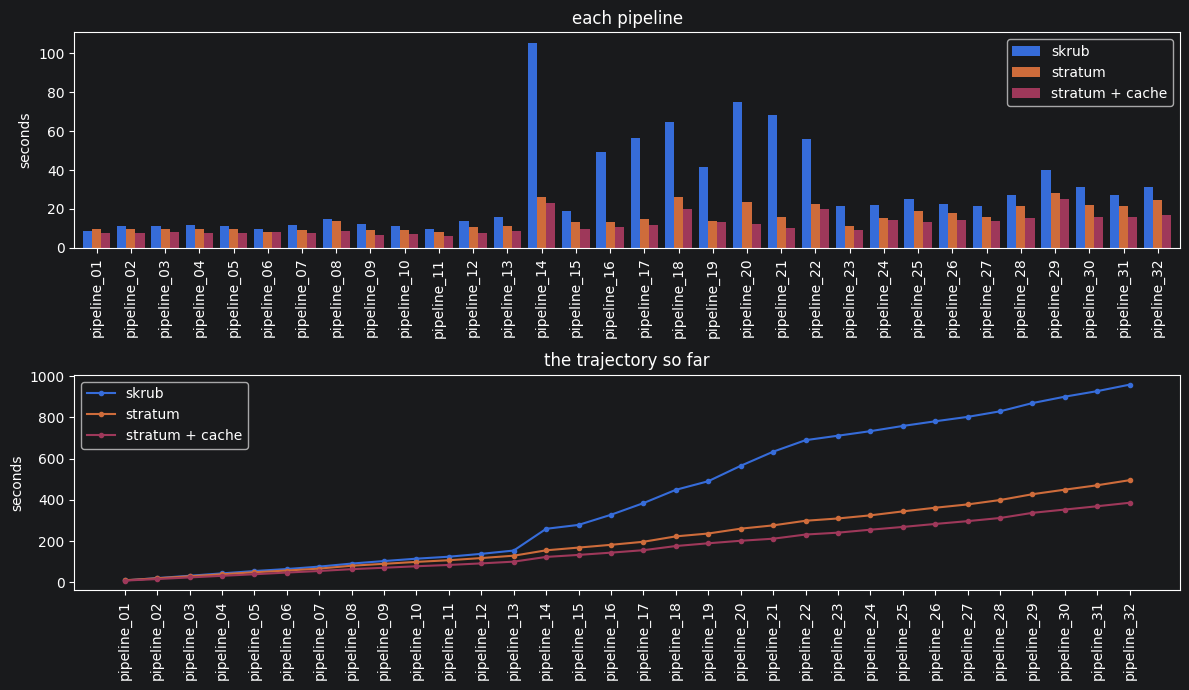

In [9]:
import matplotlib.pyplot as plt

fig, (per_pipeline, total) = plt.subplots(2, 1, figsize=(12, 7))
seconds.plot.bar(ax=per_pipeline, width=0.8)
per_pipeline.set_ylabel("seconds")
per_pipeline.set_title("each pipeline")
seconds.cumsum().reset_index(drop=True).plot(ax=total, marker=".")
total.set_xticks(range(len(seconds)), seconds.index, rotation=90)
total.set_ylabel("seconds")
total.set_title("the trajectory so far")
fig.tight_layout()

The agent's progress: each pipeline's best score, and the best so far.

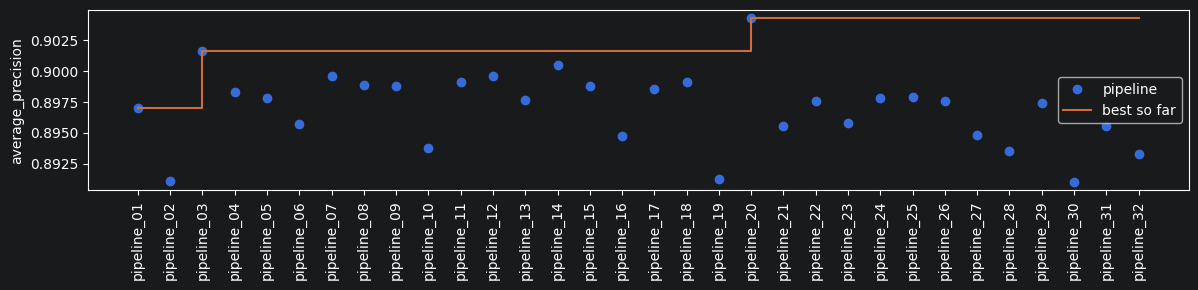

In [10]:
fig, ax = plt.subplots(figsize=(12, 3))
score = scores["stratum + cache"].astype(float)
ax.plot(score.index, score, "o", label="pipeline")
ax.step(score.index, score.cummax(), where="post", label="best so far")
ax.set_ylabel(SCORING)
ax.tick_params(axis="x", rotation=90)
ax.legend()
fig.tight_layout()

## 7. In the inspector

With `--diagnostics-dir`, the **Server** view lists the session's grid_search calls,
two per pipeline (the uncached replay's and the cached one's), the cache's size over
time and the entries each call added; each call links its run, with the executed plan
and the reuse decision of each of its ops.

In [11]:
{key: value for key, value in client.stats().items() if key != "stats"}

{'jobs': 64,
 'entries': 490,
 'memory_usage': 2258998564,
 'disk_usage': 0,
 'cache_dir': '/home/estrauss-ldap/repos/stratum/.stratum/reuse_cache'}

In [12]:
client.close()